# **ASSUMPTIONS AND LINEAR REGRESSION on House Price Regression Dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DTU AIML LAB/house_price_regression_dataset.csv')

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# **STEP : 1 PREPARE DATASET**

In [ ]:
df

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
...,...,...,...,...,...,...,...,...
995,3261,4,1,1978,2.165110,2,10,7.014940e+05
996,3179,1,2,1999,2.977123,1,10,6.837232e+05
997,2606,4,2,1962,4.055067,0,2,5.720240e+05
998,4723,5,2,1950,1.930921,0,7,9.648653e+05


In [ ]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


# **EDA**

In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nStatistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

Shape: (1000, 8)

Columns:
Index(['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built',
       'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price'],
      dtype='object')

Data Types:
Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

Statistics:
       Square_Footage  Num_Bedrooms  Num_Bathrooms   Year_Built     Lot_Size  \
count     1000.000000   1000.000000    1000.000000  1000.000000  1000.000000   
mean      2815.422000      2.990000       1.973000  1986.550000     2.778087   
std       1255.514921      1.427564       0.820332    20.632916     1.297903   
min        503.000000      1.000000       1.000000  1950.000000     0.506058   
25%       1749.500000      2.000000       1.000000  1969.000000     1.665946   
50%       2862.500000      3.

# **STEP 2 — Select our variables**

In [ ]:
# reduce the total date from 1000, 8 to 100 , 8
df = df.sample(n=65, random_state=42)

# SELECT X => Independent variables / Features (EXCEPT HOUSE_PRICE all other attributes)
X = df.drop("House_Price", axis=1)

# SELECT Y => Dependent variable / Target
y = df["House_Price"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Features (X):
     Square_Footage  Num_Bedrooms  Num_Bathrooms  Year_Built  Lot_Size  \
521            4012             3              1        2016  2.098092   
737            2310             3              1        1988  1.369622   
740            4708             1              3        1962  1.792970   
660            4932             2              1        1972  4.479598   
411            3646             1              1        1994  3.980987   

     Garage_Size  Neighborhood_Quality  
521            1                     5  
737            1                     4  
740            1                     8  
660            1                     2  
411            0                     9  

Target (y):
521    9.010005e+05
737    4.945375e+05
740    9.494042e+05
660    1.040389e+06
411    7.940100e+05
Name: House_Price, dtype: float64

Shape of X: (65, 7)
Shape of y: (65,)


In [ ]:
correlation = df.corr()

print(correlation["House_Price"].sort_values(ascending=False))

House_Price             1.000000
Square_Footage          0.993539
Year_Built              0.178088
Num_Bathrooms           0.078175
Lot_Size                0.064597
Garage_Size             0.050728
Neighborhood_Quality   -0.009828
Num_Bedrooms           -0.129438
Name: House_Price, dtype: float64


In [ ]:
# plt.figure(figsize=(10, 7))

# sns.heatmap(
#     correlation,
#     annot=True,
#     cmap="coolwarm",
#     fmt=".2f"
# )

# plt.title("Correlation Matrix")
# plt.show()

# **PLOT OF HOUSE PRICE VS SQUARE FEET**

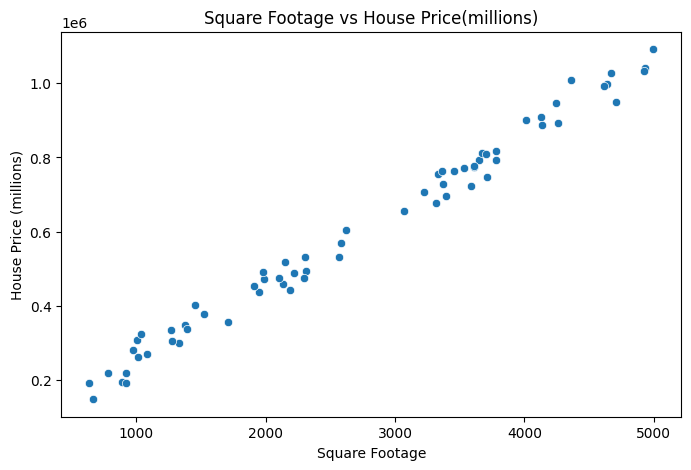

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Square_Footage",
    y="House_Price"
)

plt.title("Square Footage vs House Price(millions)")
plt.xlabel("Square Footage")
plt.ylabel("House Price (millions)")

plt.show()

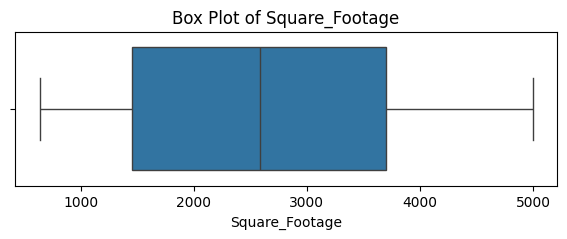

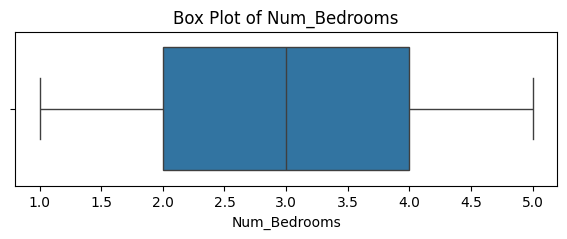

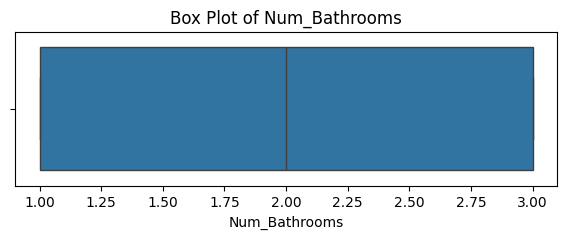

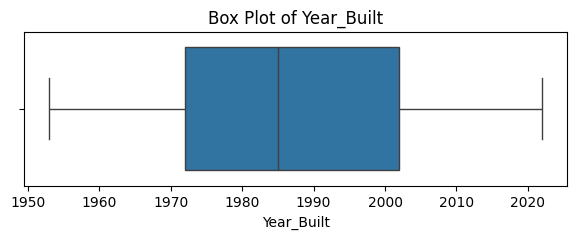

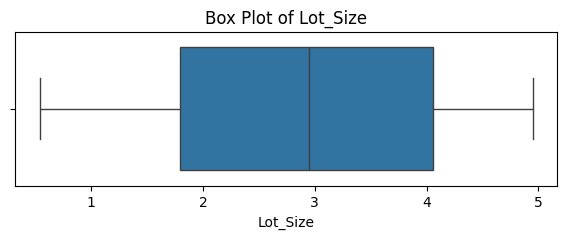

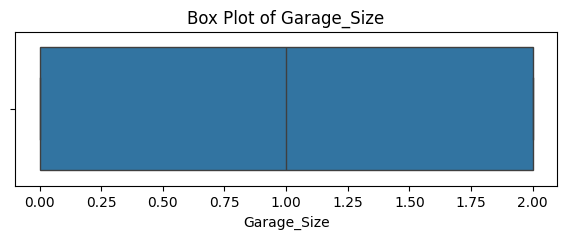

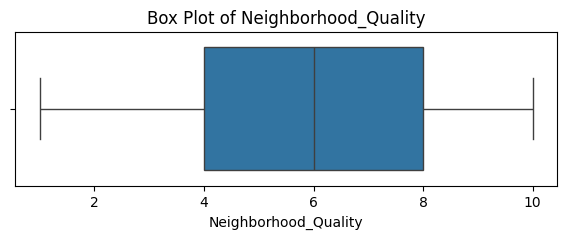

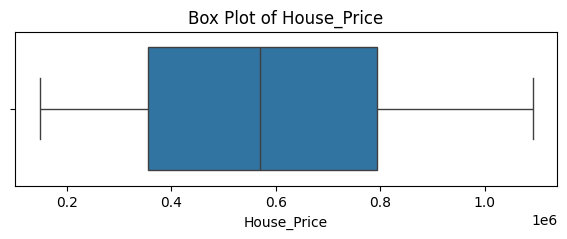

In [ ]:

for column in df.columns:

    plt.figure(figsize=(7, 2))

    sns.boxplot(x=df[column])

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.show()

# **TEST - 1 : LINEARITY TEST**

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
# make the model
model = LinearRegression()
# fit x and y values in model
model.fit(X, y)
# the predicted values are the y predicted
y_pred = model.predict(X)
# error / residuals = actual - predicted values
residuals = y - y_pred

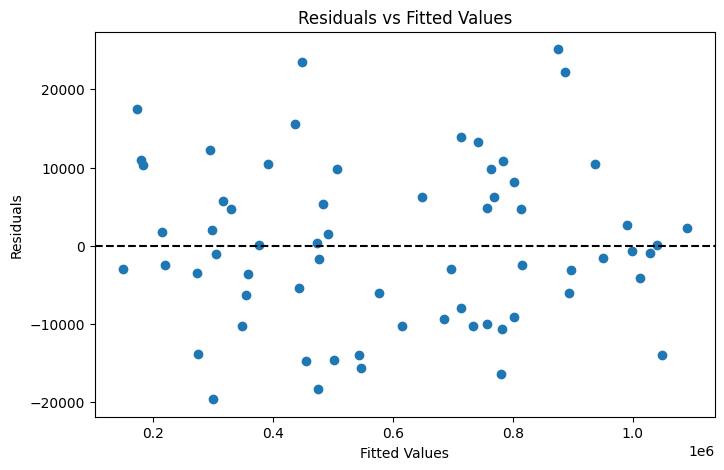

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")

plt.show()

Linearity test PASS. The residuals are randomly scattered around zero with no clear curved pattern.

# **TEST 2 : DURBIN WATSON TEST (INDEPENDENCE OF VARIABLES)**

In [ ]:
dw = np.sum(np.diff(residuals) ** 2) / np.sum(residuals ** 2)
print("Durbin-Watson Statistic:", dw)

Durbin-Watson Statistic: 1.57934485681515


2.0666573671556048 IS VERY CLOSE TO 2. SO VARIABLES ARE INDEPENDENT OF EACH OTHER, THUS DURBIN WATSON TEST PASSES


# **TEST 3: Breusch-Pagan test [Homoscedasticity] (Constant Variance of Errors)**

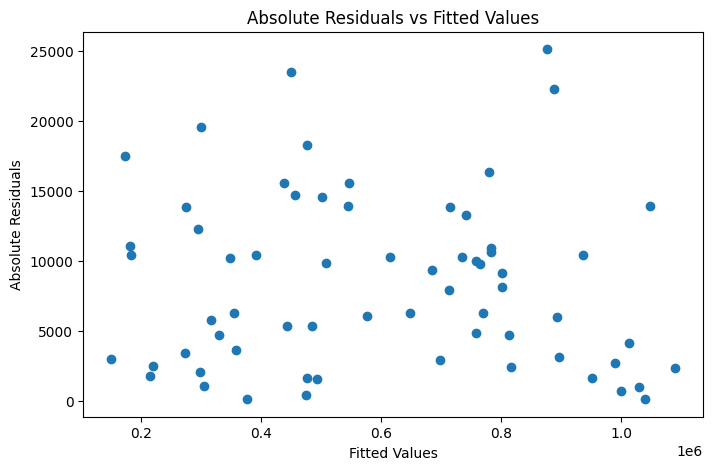

In [ ]:
absolute_residuals = np.abs(residuals)
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, absolute_residuals)
plt.xlabel("Fitted Values")
plt.ylabel("Absolute Residuals")
plt.title("Absolute Residuals vs Fitted Values")
plt.show()

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# Add constant to X
X_const = sm.add_constant(X)

# Breusch-Pagan test
bp_test = het_breuschpagan(residuals, X_const)

lm_statistic = bp_test[0]
lm_pvalue = bp_test[1]
f_statistic = bp_test[2]
f_pvalue = bp_test[3]

print("Breusch-Pagan test:")
print(f"LM Statistic: {lm_statistic:.4f}   LM p-value: {lm_pvalue:.4f}")
print(f"F-Statistic: {f_statistic:.4f}    F p-value: {f_pvalue:.4f}")

Breusch-Pagan test:
LM Statistic: 9.1734   LM p-value: 0.2404
F-Statistic: 1.3380    F p-value: 0.2496


BOTH Both p-values (0.5561 and 0.5578) are greater than 0.05.

Homoscedasticity is satisfied. Bresuch Pagen test PASS.
There is a constant spread. No cone or funnel shape spread

# **TEST 4 — Normality of Residuals**

# **4.1 Q-Q Plot**

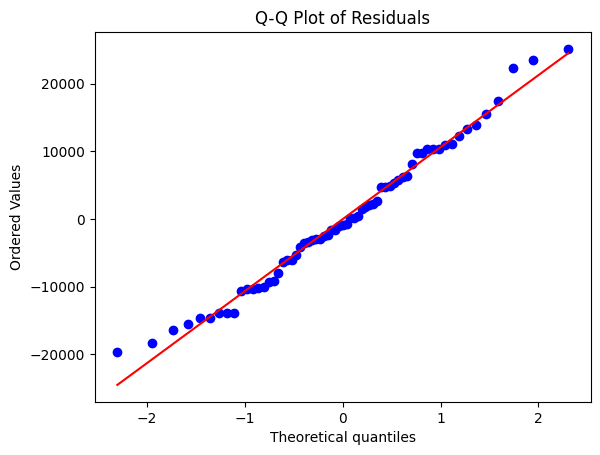

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")
plt.show()

4.2 Shapiro-Wilk Test

In [ ]:
stat, p_value = stats.shapiro(residuals)

print("Shapiro-Wilk Test:")
print("Statistic:", stat)
print("p-value:", p_value)

Shapiro-Wilk Test:
Statistic: 0.9816218712798295
p-value: 0.44546825582729094


The Q-Q plot points closely follow the diagonal line, and

p-value (0.4454 > 0.05) => residuals are normally distributed

SO NORMALITY OF RESIDUALS SATISFIED as shapiro wilk test passed

# **TEST 5 — Multicollinearity**

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# now we calculate the VIF values for X or independent variable
vif = [variance_inflation_factor(X.values, i)
       for i in range(X.shape[1])]

# print all VIFs |values
for i in range(X.shape[1]):
    print(X.columns[i], ":", vif[i])

Square_Footage : 5.5512713425880165
Num_Bedrooms : 6.830352568648739
Num_Bathrooms : 6.906767040979326
Year_Built : 36.95557331326881
Lot_Size : 5.975708348602779
Garage_Size : 3.103098306892731
Neighborhood_Quality : 6.366681877210546


Square_Footage        : 5.5513  → High

Num_Bedrooms          : 6.8304  → High

Num_Bathrooms         : 6.9068  → High

Year_Built            : 36.9556 → Very High

Lot_Size              : 5.9757  → High

Garage_Size           : 3.1031  → Acceptable

Neighborhood_Quality  : 6.3667  → High


TEST FAILED — Multicollinearity is present in the dataset, with
Year_Built showing particularly high multicollinearity
(VIF = 36.9556).

# **TEST 6 — Influential Outliers [COOKS'S DISTANCE](basically check if outliers are effecting the predicted values and the result)**

In [ ]:
# Add intercept
X_matrix = np.column_stack((np.ones(len(X)), X.values))

# Hat matrix
H = X_matrix @ np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T

# Leverage values
leverage = np.diag(H)

# Number of observations and predictors
n = len(X)
p = X.shape[1]

# Mean Squared Error
MSE = np.sum(residuals ** 2) / (n - p - 1)

# Cook's Distance
cooks_distance = (
    (residuals ** 2 / ((p + 1) * MSE))
    * (leverage / (1 - leverage) ** 2)
)

print("Maximum Cook's Distance:", np.max(cooks_distance))

Maximum Cook's Distance: 0.12781642421729442


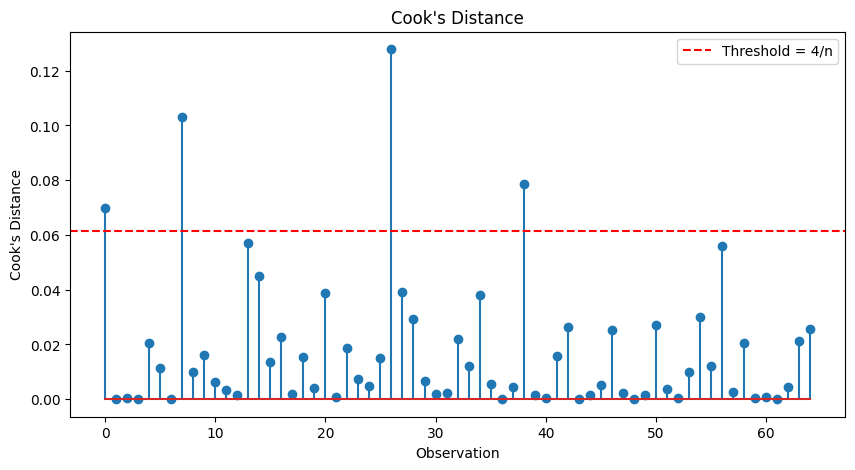

In [ ]:
plt.figure(figsize=(10, 5))

plt.stem(cooks_distance)

plt.axhline(
    4 / n,
    color="red",
    linestyle="--",
    label="Threshold = 4/n"
)

plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance")
plt.legend()

plt.show()

Influential observations are present.

cook's distance : 0.12781642421729442 > 0.004 => INFLUENTIAL OUTLIERS ARE PRESENT

thus => FAIL

Meaning , the present outliers can change the prediction and can change the output of the regression model

# ***MULTI LINEAR REGRESSION IMPLEMENTATION***

# **STEP 1: TRAIN-TEST SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (52, 7)
X_test : (13, 7)
y_train: (52,)
y_test : (13,)


# **STEP 2: ADD INTERCEPT COLUMN**
y=β0​+β1​X1​+β2​X2​+...+β7​X7​


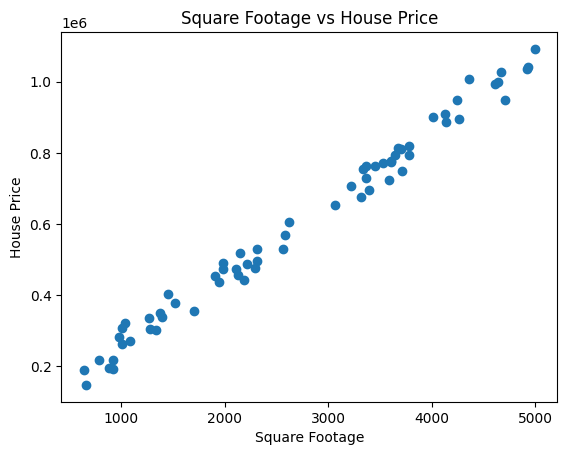

In [ ]:
plt.scatter(
    df["Square_Footage"],
    df["House_Price"]
)

plt.title("Square Footage vs House Price")
plt.xlabel("Square Footage")
plt.ylabel("House Price")

plt.show()

In [ ]:
print(df.corr())

                      Square_Footage  Num_Bedrooms  Num_Bathrooms  Year_Built  \
Square_Footage              1.000000     -0.160123       0.077605    0.106454   
Num_Bedrooms               -0.160123      1.000000      -0.114132    0.006247   
Num_Bathrooms               0.077605     -0.114132       1.000000   -0.048379   
Year_Built                  0.106454      0.006247      -0.048379    1.000000   
Lot_Size                    0.011434     -0.152036      -0.180440   -0.118074   
Garage_Size                 0.013037     -0.155287       0.118358    0.312273   
Neighborhood_Quality        0.008206     -0.191752       0.073241   -0.170238   
House_Price                 0.993539     -0.129438       0.078175    0.178088   

                      Lot_Size  Garage_Size  Neighborhood_Quality  House_Price  
Square_Footage        0.011434     0.013037              0.008206     0.993539  
Num_Bedrooms         -0.152036    -0.155287             -0.191752    -0.129438  
Num_Bathrooms        -0.180

In [ ]:
X = df[
    [
        "Square_Footage",
        "Num_Bedrooms",
        "Num_Bathrooms",
        "Year_Built",
        "Lot_Size",
        "Garage_Size",
        "Neighborhood_Quality"
    ]
]

# Dependent variable (target)
y = df["House_Price"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("Actual:")
print(y_test.values)

print("\nPredicted:")
print(y_pred)

Actual:
[ 705754.43197836  993273.07966063  901000.48823382 1008539.15623435
  724033.56045713  377511.26849809  441315.08847494  217462.44505709
  604936.83045278  270230.63769828  338350.59543444  947490.77747782
  307101.68583856]

Predicted:
[ 713999.68523485  990119.45380648  873348.96562868 1011340.60958673
  735345.10340004  379087.5539995   458728.13511526  218396.38558148
  615782.56605398  275922.45111719  349757.04951436  932869.45416911
  294613.06467087]


In [ ]:
comparison = pd.DataFrame({
    "Actual House Price": np.round(y_test.values).astype(int),
    "Predicted House Price": np.round(y_pred).astype(int)
})

comparison

,Actual House Price,Predicted House Price
0,705754,714000
1,993273,990119
2,901000,873349
3,1008539,1011341
4,724034,735345
5,377511,379088
6,441315,458728
7,217462,218396
8,604937,615783
9,270231,275922


In [ ]:
# errors = (actual - perdicted)
errors = y_test.values - y_pred

print(errors)

[ -8245.25325649   3153.62585414  27651.52260514  -2801.45335238
 -11311.5429429   -1576.28550141 -17413.04664032   -933.94052439
 -10845.7356012   -5691.81341891 -11406.45407992  14621.32330871
  12488.6211677 ]


In [ ]:
print("Absolute errors:")
print(np.abs(errors))

Absolute errors:
[ 8245.25325649  3153.62585414 27651.52260514  2801.45335238
 11311.5429429   1576.28550141 17413.04664032   933.94052439
 10845.7356012   5691.81341891 11406.45407992 14621.32330871
 12488.6211677 ]


In [ ]:
print("Squared errors:")
print(errors ** 2)

Squared errors:
[6.79842013e+07 9.94535603e+06 7.64606702e+08 7.84814089e+06
 1.27951004e+08 2.48467598e+06 3.03214193e+08 8.72244903e+05
 1.17629981e+08 3.23967400e+07 1.30107195e+08 2.13783095e+08
 1.55965659e+08]


In [ ]:
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 148829937.52799526


In [ ]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

In [ ]:
print("\n========== MODEL EVALUATION ==========")
print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R²  :", r2)


========== MODEL EVALUATION ==========
MSE : 148829937.52799526
RMSE: 12199.587596636013
MAE : 9856.970634893232
R²  : 0.9981457257431542


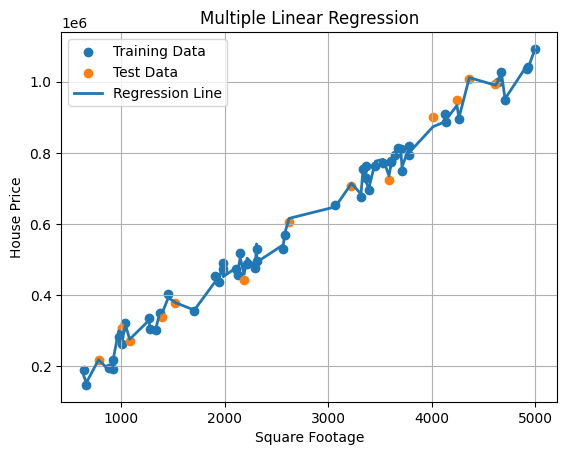

In [ ]:
plt.scatter(
    X_train["Square_Footage"],
    y_train,
    label="Training Data"
)

plt.scatter(
    X_test["Square_Footage"],
    y_test,
    label="Test Data"
)

# Sort values so the regression line is drawn correctly
sorted_indices = X["Square_Footage"].argsort()

plt.plot(
    X["Square_Footage"].iloc[sorted_indices],
    model.predict(X).reshape(-1)[sorted_indices],
    linewidth=2,
    label="Regression Line"
)

plt.title("Multiple Linear Regression")
plt.xlabel("Square Footage")
plt.ylabel("House Price")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:

new_house = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

prediction = model.predict(new_house)

print("Actual House Price:", round(actual_price, 2))
print("Predicted House Price:", round(prediction[0], 2))

Actual House Price: 705754.43
Predicted House Price: 713999.69


In [ ]:
print("Model performance:", r2 * 100, "%")

Model performance: 99.81457257431542 %
